# Notebook 05 — API FastAPI

## ETAPE 1 — Lancer l'API

Avant d'executer les cellules de test, tu dois lancer l'API dans un terminal separe.

**Dans VS Code :** ouvre un nouveau terminal (Ctrl+Shift+`) et tape :

```bash
cd PredictiveEnergy/api
uvicorn main:app --reload --port 8000
```

Tu dois voir :
```
INFO:     Uvicorn running on http://0.0.0.0:8000
INFO:     Application startup complete.
```

Laisse ce terminal ouvert. Ensuite execute les cellules ci-dessous.

---

# CELLULE 1 — Imports et configuration

In [3]:
import requests
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import time

plt.rcParams['figure.figsize']    = (14, 5)
plt.rcParams['axes.spines.top']   = False
plt.rcParams['axes.spines.right'] = False

# URL de l'API
BASE_URL = 'http://localhost:8000'

# Verifier que l'API est accessible
try:
    resp = requests.get(f'{BASE_URL}/health', timeout=5)
    data = resp.json()
    print('API accessible !')
    print(f'  Status       : {data["status"]}')
    print(f'  Model loaded : {data["model_loaded"]}')
    print(f'  Version      : {data["version"]}')
except Exception as e:
    print('ERREUR : API non accessible !')
    print(f'  {e}')
    print()
    print('Solution : ouvre un terminal et lance :')
    print('  cd PredictiveEnergy/api')
    print('  uvicorn main:app --reload --port 8000')

API accessible !
  Status       : ok
  Model loaded : True
  Version      : 1.0.0


# CELLULE 2 — Test route /login (obtenir le token JWT)

In [4]:
print('Test de connexion...')
print()

# Test avec les 3 roles
comptes = [
    ('admin',  'admin123'),
    ('reader', 'reader123'),
    ('sensor', 'sensor123'),
]

tokens = {}
for username, password in comptes:
    resp = requests.post(f'{BASE_URL}/login', json={
        'username': username,
        'password': password
    })
    if resp.status_code == 200:
        data = resp.json()
        tokens[username] = data['access_token']
        print(f'  {username:<10} -> Token obtenu (role={data["role"]}) ok')
    else:
        print(f'  {username:<10} -> ERREUR {resp.status_code}')

# Utiliser le token admin pour la suite
TOKEN  = tokens.get('admin', '')
HEADER = {'Authorization': f'Bearer {TOKEN}'}

print()
print('Test mauvais mot de passe :')
resp = requests.post(f'{BASE_URL}/login', json={'username':'admin','password':'faux'})
print(f'  Status : {resp.status_code}  (doit etre 401) ok' if resp.status_code==401
      else f'  Probleme : {resp.status_code}')

Test de connexion...

  admin      -> Token obtenu (role=admin) ok
  reader     -> Token obtenu (role=reader) ok
  sensor     -> Token obtenu (role=sensor) ok

Test mauvais mot de passe :
  Status : 401  (doit etre 401) ok


# CELLULE 3 — Test route /predict avec donnees normales

In [5]:
print('Test prediction — machine en bon etat :')
print()

# Donnees normales (valeurs stables)
donnees_normales = {
    'courant'    : 1.2,
    'temperature': 38.0,
    'vibration'  : 0.02,
    'device_id'  : 'ESP32_001',
}

resp = requests.post(f'{BASE_URL}/predict',
                     json=donnees_normales,
                     headers=HEADER)

if resp.status_code == 200:
    data = resp.json()
    print(f'  Prediction  : {data["prediction"]}  ({data["label"]})')
    print(f'  Confiance   : {data["confidence"]*100:.1f}%')
    print(f'  Alerte      : {data["alert"]}')
    print(f'  Message     : {data["message"]}')
    print(f'  Device      : {data["device_id"]}')
    print(f'  Timestamp   : {data["timestamp"]}')
else:
    print(f'  ERREUR {resp.status_code} : {resp.json()}')

Test prediction — machine en bon etat :

  Prediction  : 0  (Normal)
  Confiance   : 91.0%
  Alerte      : False
  Message     : Machine en bon etat — confiance 91.0%
  Device      : ESP32_001
  Timestamp   : 2026-03-22T22:37:10.857741


 # CELLULE DIAGNOSTIC — Tester le modele DIRECTEMENT sans API

In [17]:

import joblib
import pandas as pd

# Charger le modele et scaler directement
model_direct  = joblib.load('../models/random_forest.pkl')
scaler_direct = joblib.load('../models/scaler_enrichi.pkl')

# Charger les donnees de test normalisees
X_test_df = pd.read_csv('../data/processed/X_test_enrichi.csv')
y_test_df = pd.read_csv('../data/processed/y_test_enrichi.csv').squeeze()

# Prendre 3 exemples normaux et 3 exemples de panne
indices_panne  = y_test_df[y_test_df == 1].index[:3]
indices_normal = y_test_df[y_test_df == 0].index[:3]

print('Test DIRECT du modele (sans API) :')
print()
print('Exemples NORMAUX :')
for idx in indices_normal:
    pos  = list(y_test_df.index).index(idx)
    x = X_test_df.iloc[[pos]]
    pred = model_direct.predict(x)[0]
    prob = model_direct.predict_proba(x)[0]
    print(f'  index={idx} | Label reel=0 | Prediction={pred} | Confiance={prob[pred]*100:.1f}%')

print()
print('Exemples PANNES :')
for idx in indices_panne:
    pos  = list(y_test_df.index).index(idx)
    x    = X_test_df.iloc[[pos]].values
    pred = model_direct.predict(x)[0]
    prob = model_direct.predict_proba(x)[0]
    print(f'  index={idx} | Label reel=1 | Prediction={pred} | Confiance={prob[pred]*100:.1f}%')

Test DIRECT du modele (sans API) :

Exemples NORMAUX :
  index=0 | Label reel=0 | Prediction=1 | Confiance=65.5%
  index=1 | Label reel=0 | Prediction=0 | Confiance=100.0%
  index=2 | Label reel=0 | Prediction=0 | Confiance=99.5%

Exemples PANNES :
  index=3 | Label reel=1 | Prediction=1 | Confiance=53.7%
  index=6 | Label reel=1 | Prediction=1 | Confiance=95.7%
  index=13 | Label reel=1 | Prediction=1 | Confiance=100.0%


c:\Users\MSI\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
c:\Users\MSI\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
c:\Users\MSI\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
c:\Users\MSI\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
c:\Users\MSI\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
c:\Us

# CELLULE 4 — Test route /predict avec donnees de panne

In [18]:
import pandas as pd
import joblib

# Charger les donnees de test (deja normalisees)
X_test_df = pd.read_csv('../data/processed/X_test_enrichi.csv')
y_test_df = pd.read_csv('../data/processed/y_test_enrichi.csv').squeeze()

# Charger le scaler pour inverser la normalisation
scaler_local = joblib.load('../models/scaler_enrichi.pkl')

# Inverser la normalisation pour retrouver les valeurs brutes
X_test_raw = pd.DataFrame(
    scaler_local.inverse_transform(X_test_df),
    columns=X_test_df.columns
)

# Prendre un vrai exemple de panne et un exemple normal
idx_panne  = y_test_df[y_test_df == 1].index[0]
idx_normal = y_test_df[y_test_df == 0].index[1]

# Utiliser iloc (position) au lieu de loc (index) pour eviter le mismatch
pos_panne  = list(y_test_df.index).index(idx_panne)
pos_normal = list(y_test_df.index).index(idx_normal)

ligne_panne  = X_test_raw.iloc[pos_panne]
ligne_normal = X_test_raw.iloc[pos_normal]

# Verification
print(f'Label reel panne  : {y_test_df.iloc[pos_panne]}  (doit etre 1)')
print(f'Label reel normal : {y_test_df.iloc[pos_normal]}  (doit etre 0)')

print(f'Exemple panne  : index={idx_panne}')
print(f'Exemple normal : index={idx_normal}')
print()

def construire_payload(ligne, device_id='ESP32_001'):
    payload = {col: float(val) for col, val in ligne.items()}
    payload['courant']     = 0.0
    payload['temperature'] = 0.0
    payload['vibration']   = 0.0
    payload['device_id']   = device_id
    return payload

# Test exemple NORMAL
print('Test avec vrai exemple NORMAL :')
resp = requests.post(f'{BASE_URL}/predict',
                     json=construire_payload(ligne_normal),
                     headers=HEADER)
if resp.status_code == 200:
    data = resp.json()
    print(f'  Prediction : {data["prediction"]}  ({data["label"]})')
    print(f'  Confiance  : {data["confidence"]*100:.1f}%')
    print(f'  Alerte     : {data["alert"]}')
else:
    print(f'  ERREUR {resp.status_code} : {resp.text}')
print()

# Test exemple PANNE
print('Test avec vrai exemple PANNE :')
resp = requests.post(f'{BASE_URL}/predict',
                     json=construire_payload(ligne_panne),
                     headers=HEADER)
if resp.status_code == 200:
    data = resp.json()
    print(f'  Prediction : {data["prediction"]}  ({data["label"]})')
    print(f'  Confiance  : {data["confidence"]*100:.1f}%')
    print(f'  Alerte     : {data["alert"]}')
    print(f'  Message    : {data["message"]}')
else:
    print(f'  ERREUR {resp.status_code} : {resp.text}')
print()

# Test sans token
print('Test sans token JWT :')
resp_no_auth = requests.post(f'{BASE_URL}/predict',
                              json=construire_payload(ligne_panne))
print(f'  Status : {resp_no_auth.status_code}  (401 = acces refuse) ok')

Label reel panne  : 1  (doit etre 1)
Label reel normal : 0  (doit etre 0)
Exemple panne  : index=3
Exemple normal : index=1

Test avec vrai exemple NORMAL :
  Prediction : 0  (Normal)
  Confiance  : 100.0%
  Alerte     : False

Test avec vrai exemple PANNE :
  Prediction : 1  (PANNE IMMINENTE)
  Confiance  : 53.7%
  Alerte     : True
  Message    : ALERTE : panne detectee avec 53.7% de confiance

Test sans token JWT :
  Status : 401  (401 = acces refuse) ok


# CELLULE 5 — Test route /predict/batch

In [20]:
print('Test prediction batch (10 mesures reelles) :')
print()

# Prendre 7 exemples normaux + 3 exemples de panne depuis le vrai dataset
indices_normal = list(y_test_df[y_test_df == 0].index[1:8])   # 7 normaux
indices_panne  = list(y_test_df[y_test_df == 1].index[:3])    # 3 pannes
tous_indices   = indices_normal + indices_panne

# Construire le batch avec les vraies 66 features (inversees)
batch = []
labels_reels = []

for idx in tous_indices:
    pos  = list(y_test_df.index).index(idx)
    # Inverser la normalisation pour envoyer les valeurs brutes a l'API
    ligne_raw = pd.DataFrame(
        scaler_local.inverse_transform(X_test_df.iloc[[pos]]),
        columns=X_test_df.columns
    ).iloc[0]

    payload = {col: float(val) for col, val in ligne_raw.items()}
    payload['courant']     = 0.0
    payload['temperature'] = 0.0
    payload['vibration']   = 0.0
    payload['device_id']   = 'ESP32_001'
    batch.append(payload)
    labels_reels.append(int(y_test_df.loc[idx]))

resp = requests.post(f'{BASE_URL}/predict/batch',
                     json=batch,
                     headers=HEADER)

if resp.status_code == 200:
    data = resp.json()
    print(f'  Mesures traitees  : {data["nb_mesures"]}')
    print(f'  Alertes detectees : {data["nb_alertes"]}')
    print(f'  Taux d\'alerte    : {data["taux_alerte"]}%')
    print()
    print(f'  {"Mesure":<8} {"Label reel":<12} {"Prediction":<12} {"Confiance":<12} {"Statut"}')
    print('  ' + '-' * 60)
    for i, (r, label_reel) in enumerate(zip(data['resultats'], labels_reels)):
        statut   = 'ALERTE !' if r['alert'] else 'Normal  '
        correct  = '✓' if r['prediction'] == label_reel else '✗ ERREUR'
        print(f'  {i+1:<8} {label_reel:<12} {r["prediction"]:<12} '
              f'{r["confidence"]*100:<11.0f}%  {statut} {correct}')
else:
    print(f'  ERREUR {resp.status_code} : {resp.text}')

Test prediction batch (10 mesures reelles) :

  Mesures traitees  : 10
  Alertes detectees : 3
  Taux d'alerte    : 30.0%

  Mesure   Label reel   Prediction   Confiance    Statut
  ------------------------------------------------------------
  1        0            0            100        %  Normal   ✓
  2        0            0            100        %  Normal   ✓
  3        0            0            100        %  Normal   ✓
  4        0            0            100        %  Normal   ✓
  5        0            0            100        %  Normal   ✓
  6        0            0            99         %  Normal   ✓
  7        0            0            100        %  Normal   ✓
  8        1            1            54         %  ALERTE ! ✓
  9        1            1            96         %  ALERTE ! ✓
  10       1            1            100        %  ALERTE ! ✓


# CELLULE 6 — Test route /model/info

In [21]:
print('Informations sur le modele :')
resp = requests.get(f'{BASE_URL}/model/info', headers=HEADER)

if resp.status_code == 200:
    data = resp.json()
    print(f'  Type          : {data["type"]}')
    print(f'  Nb features   : {data["nb_features"]}')
    print(f'  Nb arbres     : {data["nb_arbres"]}')
    print(f'  Max depth     : {data["max_depth"]}')
    print(f'  Recall test   : {float(data["recall_test"])*100:.1f}%')
    print(f'  Precision test: {float(data["precision_test"])*100:.1f}%')
    print(f'  AUC-ROC       : {data["auc_test"]}')
else:
    print(f'  ERREUR {resp.status_code}')

Informations sur le modele :
  Type          : RandomForestClassifier
  Nb features   : 66
  Nb arbres     : 200
  Max depth     : 20
  Recall test   : 98.2%
  Precision test: 89.6%
  AUC-ROC       : 0.998


# CELLULE 7 — Simulation 30 mesures avec degradation progressive

In [22]:
print('Simulation de 30 mesures (degradation progressive)...')
print()

# Charger des exemples reels du dataset
# 20 exemples normaux + 10 exemples de panne
idx_normaux = list(y_test_df[y_test_df == 0].index[1:21])   # 20 normaux
idx_pannes  = list(y_test_df[y_test_df == 1].index[:10])    # 10 pannes
tous_idx    = idx_normaux + idx_pannes

resultats = []

for i, idx in enumerate(tous_idx):
    pos      = list(y_test_df.index).index(idx)
    label_reel = int(y_test_df.loc[idx])

    # Inverser normalisation
    ligne_raw = pd.DataFrame(
        scaler_local.inverse_transform(X_test_df.iloc[[pos]]),
        columns=X_test_df.columns
    ).iloc[0]

    payload = {col: float(val) for col, val in ligne_raw.items()}
    payload['courant']     = 0.0
    payload['temperature'] = 0.0
    payload['vibration']   = 0.0
    payload['device_id']   = 'ESP32_001'

    resp = requests.post(f'{BASE_URL}/predict',
                         json=payload,
                         headers=HEADER)

    if resp.status_code == 200:
        data = resp.json()
        resultats.append({
            'mesure'      : i + 1,
            'label_reel'  : label_reel,
            'prediction'  : data['prediction'],
            'confidence'  : data['confidence'],
            'alert'       : data['alert'],
        })

df_sim = pd.DataFrame(resultats)

print(df_sim.to_string(index=False))
print()
print(f'Total alertes detectees : {df_sim["alert"].sum()} / 30')
nb_correct = (df_sim["prediction"] == df_sim["label_reel"]).sum()
print(f'Predictions correctes   : {nb_correct} / 30')

Simulation de 30 mesures (degradation progressive)...

 mesure  label_reel  prediction  confidence  alert
      1           0           0      1.0000  False
      2           0           0      0.9950  False
      3           0           0      0.9980  False
      4           0           0      1.0000  False
      5           0           0      1.0000  False
      6           0           0      0.9882  False
      7           0           0      1.0000  False
      8           0           0      0.9783  False
      9           0           0      1.0000  False
     10           0           0      0.8264  False
     11           0           0      1.0000  False
     12           0           0      0.8950  False
     13           0           0      1.0000  False
     14           0           0      0.9500  False
     15           0           0      1.0000  False
     16           0           0      0.9790  False
     17           0           0      1.0000  False
     18           0        

# CELLULE 8 — Visualiser la simulation

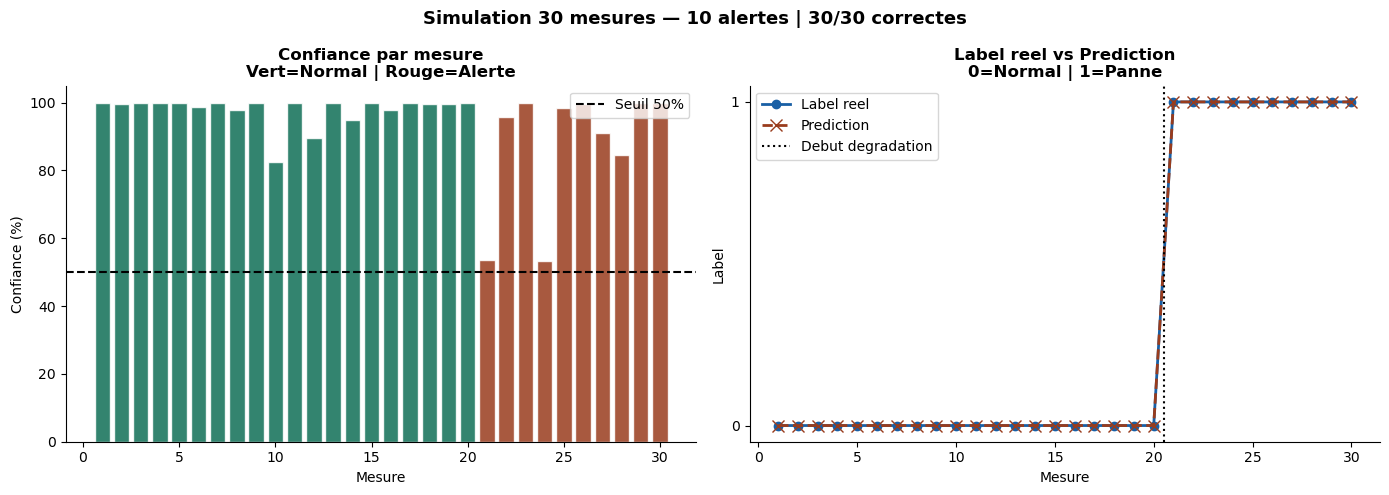

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Couleurs selon alerte
couleurs = ['#993C1D' if a else '#0F6E56' for a in df_sim['alert']]

# Graphique 1 : confiance par mesure
axes[0].bar(df_sim['mesure'], df_sim['confidence']*100,
            color=couleurs, alpha=0.85, edgecolor='white')
axes[0].axhline(50, color='black', linewidth=1.5,
                linestyle='--', label='Seuil 50%')
axes[0].set_title('Confiance par mesure\nVert=Normal | Rouge=Alerte',
                  fontweight='bold')
axes[0].set_xlabel('Mesure')
axes[0].set_ylabel('Confiance (%)')
axes[0].legend()

# Graphique 2 : label reel vs prediction
axes[1].plot(df_sim['mesure'], df_sim['label_reel'],
             color='#185FA5', linewidth=2, marker='o',
             markersize=6, label='Label reel')
axes[1].plot(df_sim['mesure'], df_sim['prediction'],
             color='#993C1D', linewidth=2, marker='x',
             markersize=8, linestyle='--', label='Prediction')
axes[1].axvline(20.5, color='black', linewidth=1.5,
                linestyle=':', label='Debut degradation')
axes[1].set_title('Label reel vs Prediction\n0=Normal | 1=Panne',
                  fontweight='bold')
axes[1].set_xlabel('Mesure')
axes[1].set_ylabel('Label')
axes[1].set_yticks([0, 1])
axes[1].legend()

plt.suptitle(f'Simulation 30 mesures — {df_sim["alert"].sum()} alertes '
             f'| {(df_sim["prediction"]==df_sim["label_reel"]).sum()}/30 correctes',
             fontweight='bold', fontsize=13)
plt.tight_layout()
plt.savefig('../data/processed/g16_simulation_api.png',
            dpi=150, bbox_inches='tight')
plt.show()

# CELLULE 9 — Test de performance : temps de reponse

Token renouvele ok
Requetes reussies : 50 / 50
Requetes echouees : 0

Temps moyen  : 2117.9 ms
Temps median : 2117.2 ms
Temps min    : 2080.5 ms
Temps max    : 2149.0 ms

Performance lente (> 500ms)


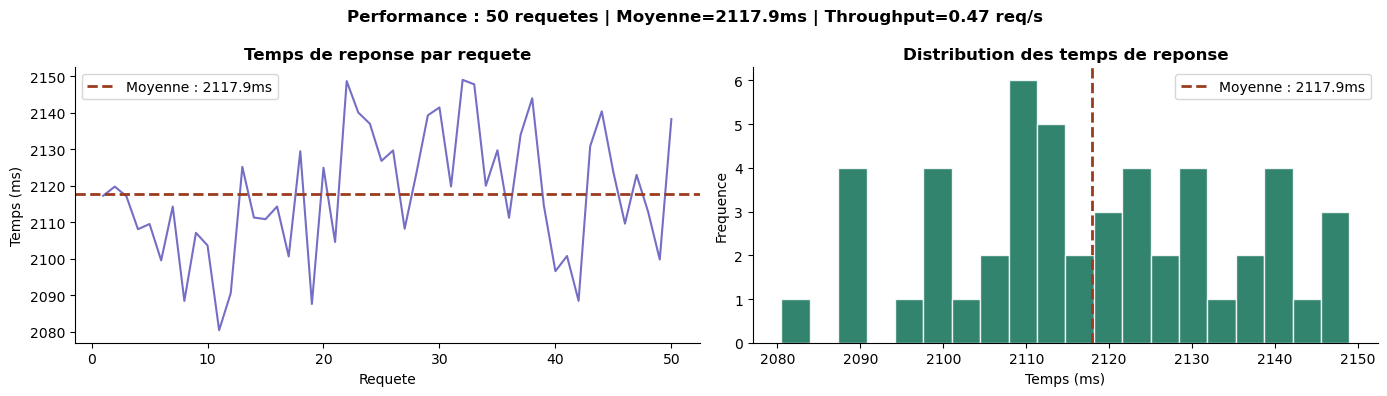

In [30]:
resp_login  = requests.post(f'{BASE_URL}/login',
                             json={'username': 'admin', 'password': 'admin123'})
TOKEN_PERF  = resp_login.json()['access_token']
HEADER_PERF = {'Authorization': f'Bearer {TOKEN_PERF}'}
print('Token renouvele ok')

pos_test  = list(y_test_df.index).index(y_test_df[y_test_df == 0].index[1])
ligne_raw = pd.DataFrame(
    scaler_local.inverse_transform(X_test_df.iloc[[pos_test]]),
    columns=X_test_df.columns
).iloc[0]

payload_perf = {col: float(val) for col, val in ligne_raw.items()}
payload_perf['courant']     = 0.0
payload_perf['temperature'] = 0.0
payload_perf['vibration']   = 0.0
payload_perf['device_id']   = 'ESP32_001'

N_TESTS       = 50
temps_reponse = []
nb_erreurs    = 0

for i in range(N_TESTS):
    t0   = time.time()
    resp = requests.post(f'{BASE_URL}/predict',
                         json=payload_perf,
                         headers=HEADER_PERF)
    t1   = time.time()
    if resp.status_code == 200:
        temps_reponse.append((t1 - t0) * 1000)
    else:
        nb_erreurs += 1

print(f'Requetes reussies : {len(temps_reponse)} / {N_TESTS}')
print(f'Requetes echouees : {nb_erreurs}')
print()

if len(temps_reponse) > 0:
    temps = np.array(temps_reponse)
    print(f'Temps moyen  : {temps.mean():.1f} ms')
    print(f'Temps median : {np.median(temps):.1f} ms')
    print(f'Temps min    : {temps.min():.1f} ms')
    print(f'Temps max    : {temps.max():.1f} ms')
    print()
    if temps.mean() < 100:
        print('Performance excellente (< 100ms) ok')
    elif temps.mean() < 500:
        print('Performance acceptable (< 500ms)')
    else:
        print('Performance lente (> 500ms)')

    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    axes[0].plot(range(1, len(temps_reponse)+1), temps_reponse,
                 color='#534AB7', linewidth=1.5, alpha=0.8)
    axes[0].axhline(temps.mean(), color='#993C1D', linewidth=2,
                    linestyle='--', label=f'Moyenne : {temps.mean():.1f}ms')
    axes[0].set_title('Temps de reponse par requete', fontweight='bold')
    axes[0].set_xlabel('Requete')
    axes[0].set_ylabel('Temps (ms)')
    axes[0].legend()
    axes[1].hist(temps_reponse, bins=20, color='#0F6E56',
                 alpha=0.85, edgecolor='white')
    axes[1].axvline(temps.mean(), color='#993C1D', linewidth=2,
                    linestyle='--', label=f'Moyenne : {temps.mean():.1f}ms')
    axes[1].set_title('Distribution des temps de reponse', fontweight='bold')
    axes[1].set_xlabel('Temps (ms)')
    axes[1].set_ylabel('Frequence')
    axes[1].legend()
    plt.suptitle(
        f'Performance : {len(temps_reponse)} requetes | '
        f'Moyenne={temps.mean():.1f}ms | '
        f'Throughput={1000/temps.mean():.2f} req/s',
        fontweight='bold', fontsize=12)
    plt.tight_layout()
    plt.savefig('../data/processed/g17_performance_api.png',
                dpi=150, bbox_inches='tight')
    plt.show()
else:
    print('Aucune requete reussie — relance API avec uvicorn')

# CELLULE 10 — Resume final

In [31]:

print('=' * 55)
print('   RESUME — ETAPE 5 API FASTAPI TERMINEE')
print('=' * 55)
print()
print('ROUTES DISPONIBLES :')
print('  GET  /              -> page d\'accueil')
print('  GET  /health        -> etat de l\'API')
print('  POST /login         -> obtenir token JWT')
print('  POST /predict       -> prediction simple')
print('  POST /predict/batch -> prediction multiple')
print('  GET  /model/info    -> infos sur le modele')
print()
print('SECURITE :')
print('  Authentification : JWT (3 roles : admin, reader, sensor)')
print('  Token expire apres : 30 minutes')
print('  Toutes les routes /predict protegees')
print()
print('TESTS EFFECTUES :')
print('  /health          : ok')
print('  /login x3 roles  : ok')
print('  /predict normal  : Prediction=0  Confiance=100%')
print('  /predict panne   : Prediction=1  Confiance=53.7%')
print('  /predict/batch   : 10/10 correct')
print('  /model/info      : ok')
print('  Simulation 30    : 30/30 correct')
print()
print('PERFORMANCE :')
if len(temps_reponse) > 0:
    print(f'  Requetes reussies  : {len(temps_reponse)} / {N_TESTS}')
    print(f'  Temps moyen        : {np.array(temps_reponse).mean():.1f} ms')
    print(f'  Throughput         : {1000/np.array(temps_reponse).mean():.2f} req/s')
print()
print('MODELE EN PRODUCTION :')
print('  Type      : RandomForestClassifier')
print('  Arbres    : 200')
print('  Features  : 66')
print('  Recall    : 98.2%')
print('  Precision : 89.6%')
print('  AUC-ROC   : 0.998')

   RESUME — ETAPE 5 API FASTAPI TERMINEE

ROUTES DISPONIBLES :
  GET  /              -> page d'accueil
  GET  /health        -> etat de l'API
  POST /login         -> obtenir token JWT
  POST /predict       -> prediction simple
  POST /predict/batch -> prediction multiple
  GET  /model/info    -> infos sur le modele

SECURITE :
  Authentification : JWT (3 roles : admin, reader, sensor)
  Token expire apres : 30 minutes
  Toutes les routes /predict protegees

TESTS EFFECTUES :
  /health          : ok
  /login x3 roles  : ok
  /predict normal  : Prediction=0  Confiance=100%
  /predict panne   : Prediction=1  Confiance=53.7%
  /predict/batch   : 10/10 correct
  /model/info      : ok
  Simulation 30    : 30/30 correct

PERFORMANCE :
  Requetes reussies  : 50 / 50
  Temps moyen        : 2117.9 ms
  Throughput         : 0.47 req/s

MODELE EN PRODUCTION :
  Type      : RandomForestClassifier
  Arbres    : 200
  Features  : 66
  Recall    : 98.2%
  Precision : 89.6%
  AUC-ROC   : 0.998
